# Breast Cancer Classification Using Logistic Regression

**Research question:** How accurately can Logistic Regression classify breast tumours as malignant or benign using diagnostic measurements?

This educational notebook uses the Breast Cancer Wisconsin (Diagnostic) dataset. It is not a clinical diagnostic tool.

**Dataset source:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic).

## 1. Import libraries
We use pandas and matplotlib for data inspection and visualisation, and scikit-learn for modelling and evaluation.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)

Matplotlib is building the font cache; this may take a moment.


## 2. Load the dataset
The dataset contains 569 observations and 30 numerical features. In scikit-learn, target 0 is malignant and target 1 is benign.

In [2]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data
y = dataset.target

df = X.copy()
df['diagnosis'] = y.map({0: 'malignant', 1: 'benign'})

print('Dataset shape:', df.shape)
print('Feature count:', X.shape[1])
print('Class distribution:')
print(df['diagnosis'].value_counts())
display(df.head())

Dataset shape: (569, 31)
Feature count: 30
Class distribution:
diagnosis
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


## 3. Explore the data
Check data types, missing values and the class distribution before modelling.

Missing values: 0
Duplicate rows: 0
Summary statistics:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10,0.09,0.05,0.18,0.06,0.41,1.22,2.87,40.34,0.01,0.03,0.03,0.01,0.02,0.00,16.27,25.68,107.26,880.58,0.13,0.25,0.27,0.11,0.29,0.08
std,3.52,4.30,24.30,351.91,0.01,0.05,0.08,0.04,0.03,0.01,0.28,0.55,2.02,45.49,0.00,0.02,0.03,0.01,0.01,0.00,4.83,6.15,33.60,569.36,0.02,0.16,0.21,0.07,0.06,0.02
min,6.98,9.71,43.79,143.50,0.05,0.02,0.00,0.00,0.11,0.05,0.11,0.36,0.76,6.80,0.00,0.00,0.00,0.00,0.01,0.00,7.93,12.02,50.41,185.20,0.07,0.03,0.00,0.00,0.16,0.06
25%,11.70,16.17,75.17,420.30,0.09,0.06,0.03,0.02,0.16,0.06,0.23,0.83,1.61,17.85,0.01,0.01,0.02,0.01,0.02,0.00,13.01,21.08,84.11,515.30,0.12,0.15,0.11,0.06,0.25,0.07
50%,13.37,18.84,86.24,551.10,0.10,0.09,0.06,0.03,0.18,0.06,0.32,1.11,2.29,24.53,0.01,0.02,0.03,0.01,0.02,0.00,14.97,25.41,97.66,686.50,0.13,0.21,0.23,0.10,0.28,0.08
75%,15.78,21.80,104.10,782.70,0.11,0.13,0.13,0.07,0.20,0.07,0.48,1.47,3.36,45.19,0.01,0.03,0.04,0.01,0.02,0.00,18.79,29.72,125.40,1084.00,0.15,0.34,0.38,0.16,0.32,0.09
max,28.11,39.28,188.50,2501.00,0.16,0.35,0.43,0.20,0.30,0.10,2.87,4.88,21.98,542.20,0.03,0.14,0.40,0.05,0.08,0.03,36.04,49.54,251.20,4254.00,0.22,1.06,1.25,0.29,0.66,0.21


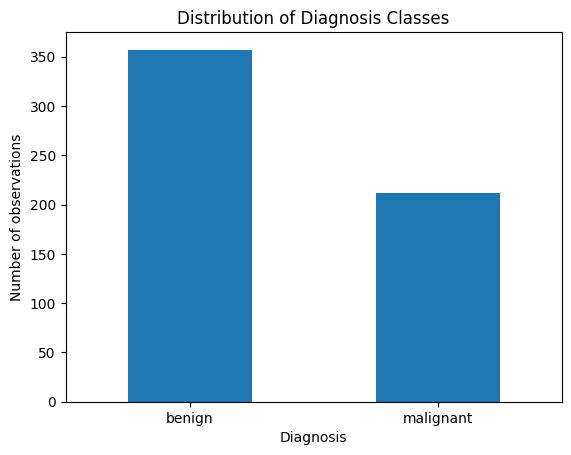

In [3]:
print('Missing values:', X.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Summary statistics:')
display(X.describe().round(2))

df['diagnosis'].value_counts().plot(kind='bar', rot=0)
plt.title('Distribution of Diagnosis Classes')
plt.xlabel('Diagnosis')
plt.ylabel('Number of observations')
plt.show()

## 4. Split the data
We reserve 20% of observations for testing. Stratification preserves the class proportions in both subsets. A fixed random state makes the split reproducible.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print('Training observations:', X_train.shape[0])
print('Testing observations:', X_test.shape[0])

Training observations: 455
Testing observations: 114


## 5. Build and train the Logistic Regression model
StandardScaler and LogisticRegression are combined in a pipeline. The scaler is fitted only on the training data, which helps prevent data leakage.

In [5]:
model = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=5000, random_state=42))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

print('Model training completed.')

Model training completed.


## 6. Evaluate model performance
The classification report shows precision, recall and F1-score for both classes. These measures provide more detail than accuracy alone.

In [6]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=0)
recall = recall_score(y_test, y_pred, pos_label=0)
f1 = f1_score(y_test, y_pred, pos_label=0)
roc_auc = roc_auc_score((y_test == 0).astype(int), y_proba[:, 0])

print(f'Accuracy:  {accuracy:.4f}')
print(f'Precision (malignant): {precision:.4f}')
print(f'Recall (malignant):    {recall:.4f}')
print(f'F1-score (malignant):  {f1:.4f}')
print(f'ROC-AUC (malignant):   {roc_auc:.4f}')
print('\nDetailed classification report:')
print(classification_report(y_test, y_pred, target_names=dataset.target_names))

Accuracy:  0.9825
Precision (malignant): 0.9762
Recall (malignant):    0.9762
F1-score (malignant):  0.9762
ROC-AUC (malignant):   0.9954

Detailed classification report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## 7. Confusion matrix
The confusion matrix compares actual and predicted classes. Rows represent actual classes and columns represent predicted classes.

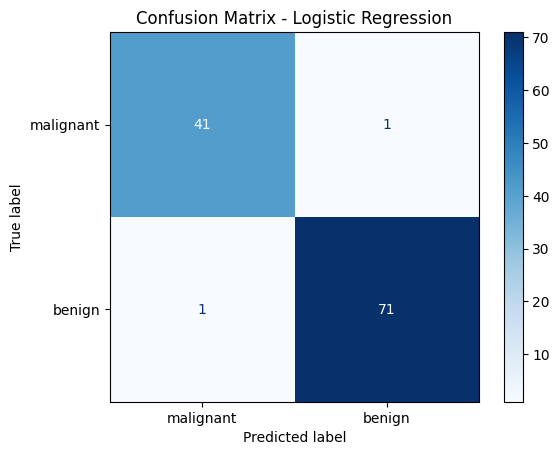

In [7]:
cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=dataset.target_names)
display.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

## 8. ROC curve
The ROC curve shows the trade-off between the true-positive rate and false-positive rate at different thresholds. Here, malignant is treated as the positive class.

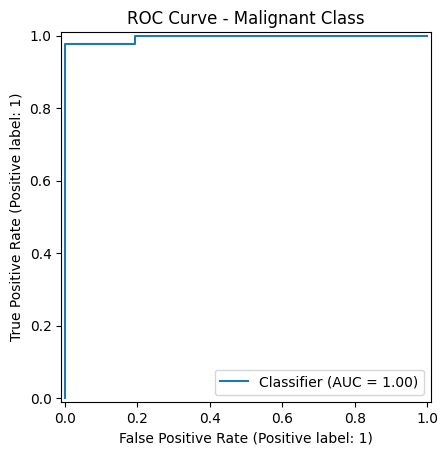

In [8]:
y_test_malignant = (y_test == 0).astype(int)
RocCurveDisplay.from_predictions(y_test_malignant, y_proba[:, 0])
plt.title('ROC Curve - Malignant Class')
plt.show()

## 9. Conclusion
Review the test metrics and plots above. State whether the model performed well on this held-out test set, identify any false negatives and false positives from the confusion matrix, and discuss limitations such as the dataset size, age and the use of a single algorithm. Do not describe this model as suitable for clinical diagnosis.

In [9]:
print('Actual class labels:', dict(enumerate(dataset.target_names)))
print('Test-set observations:', len(y_test))
print('False negatives for malignant class:', int(cm[0, 1]))
print('False positives for malignant class:', int(cm[1, 0]))

Actual class labels: {0: np.str_('malignant'), 1: np.str_('benign')}
Test-set observations: 114
False negatives for malignant class: 1
False positives for malignant class: 1
